# TD1 — Pipeline ETL de la fréquentation du réseau ferré IDFM

**Binôme : ADJAKOSSA / AKODEKOU** · Master SEP · Ingénierie des données massives (Ouael ETTOUILEB) · Remise du 1er novembre 2026

Ce notebook est le **point d'entrée manuel** du pipeline. Il n'embarque pas la logique de traitement :
il appelle les modules Python de `src/` et les scripts SQL versionnés de `sql/`, puis affiche les
résultats de collecte, de contrôle, de jointure et d'exploitation.

| Couche | Stockage | Code |
|---|---|---|
| Bronze | Cloud Storage, `bronze/<source>/snapshot=<date>/…` | `src/collect/`, `src/bronze/` |
| Silver | BigQuery, dataset Silver | `src/silver/`, `sql/silver/01…05_*.sql` |
| Gold | BigQuery, dataset Gold | `sql/gold/01…03_*.sql` |
| Contrôles | requêtes chiffrées | `sql/checks/*.sql`, `src/quality/checks.py` |

Sources : validations quotidiennes IDFM (réseau ferré), zones de correspondance IDFM, jours fériés
(zone métropole), météo quotidienne Météo-France (famille RR-T-Vent, 8 départements d'Île-de-France).
Période : années civiles 2023, 2024 et 2025.

## 0. Prérequis et paramètres

Exécution locale (Ubuntu 24.04 / WSL2), sans Colab :

1. `python3 -m venv .venv && source .venv/bin/activate && pip install -r requirements.txt` ;
2. `gcloud auth application-default login` puis
   `gcloud auth application-default set-quota-project <PROJET>` (projet facturé) ;
3. `cp .env.example .env` et renseigner les variables ; le bucket et les deux datasets doivent exister
   dans la même localisation.

Paramètres lus dans `.env` (aucune valeur n'est écrite dans le code) : projet, localisation, bucket,
datasets Silver et Gold, années de début et de fin, **date de snapshot Bronze**. Changer `SNAPSHOT_DATE`
crée un nouveau snapshot ; la conserver rejoue le pipeline sur les mêmes octets sources.

In [1]:
import sys, warnings
from pathlib import Path
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))
warnings.filterwarnings("ignore", message="BigQuery Storage module not found")

import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_colwidth", 120); pd.set_option("display.width", 250); pd.set_option("display.max_rows", 120)

from src.config import charger_config
from src import bq as B
from src.pipeline import executer, SQL_SILVER, SQL_GOLD
from src.quality.checks import executer_controles, empreintes, comparer_empreintes

config = charger_config()
bq = B.client(config)
S, G = f"{config.projet}.{config.dataset_silver}", f"{config.projet}.{config.dataset_gold}"
pd.DataFrame({"paramètre": ["projet", "localisation", "bucket", "dataset Silver", "dataset Gold", "années", "snapshot Bronze"],
              "valeur": [config.projet, config.localisation, config.bucket, config.dataset_silver,
                         config.dataset_gold, f"{config.annee_debut}–{config.annee_fin}", config.snapshot]})

,paramètre,valeur
0,projet,td-v1-511114
1,localisation,EU
2,bucket,td-v1-511114-td1-idfm
3,dataset Silver,silver_idfm
4,dataset Gold,gold_idfm
5,années,2023–2025
6,snapshot Bronze,2026-10-31


## 1. Exécution n° 1 du pipeline

Ordre : collecte Bronze → tables de chargement Silver → SQL Silver → SQL Gold. Au premier lancement
d'un snapshot, les sources sont téléchargées ; ensuite, chaque objet Bronze est **réutilisé** et son
SHA-256 est recalculé puis comparé au manifeste, sans recontacter la source.

In [2]:
execution_1 = executer(config)
pd.DataFrame(execution_1.scripts)

/home/vechoadjax/projet-python/projet TD1/.venv/lib/python3.12/site-packages/google/cloud/bigquery/_pandas_helpers.py:486: FutureWarning: Loading pandas DataFrame into BigQuery will require pandas-gbq package version 0.26.1 or greater in the future. Tried to import pandas-gbq and got: No module named 'pandas_gbq'
  warnings.warn(


,script,octets_traites,duree_s
0,silver/01_ref_categorie_titre.sql,0,1.8
1,silver/02_zones.sql,1893752,1.7
2,silver/03_validations.sql,4459244561,21.1
3,silver/04_jours_feries.sql,3462,0.5
4,silver/05_meteo.sql,1198039746,10.2
5,gold/01_dimensions.sql,46780622,8.7
6,gold/02_faits.sql,611634013,9.3
7,gold/03_kpi_et_semantique.sql,0,3.2


## 2. Bronze : provenance des objets collectés

Chaque objet porte, dans ses métadonnées GCS et dans un manifeste JSON voisin (`<objet>.manifest.json`),
l'URL, les paramètres, l'horodatage UTC de collecte, la taille et l'empreinte SHA-256. Le dépôt utilise
la précondition `if_generation_match=0` : un objet existant ne peut pas être écrasé. De plus, chaque objet
et son manifeste portent un **hold temporaire** GCS : tant qu'il est posé, Cloud Storage refuse toute
suppression ou tout remplacement, quel que soit l'outil (levée explicite : `--no-temporary-hold`).

In [3]:
bronze = execution_1.bronze
bronze[["source", "chemin_gcs", "taille_octets", "sha256", "collecte_utc", "statut_depot", "hold_temporaire"]].assign(sha256=lambda d: d.sha256.str[:16] + "…")

,source,chemin_gcs,taille_octets,sha256,collecte_utc,statut_depot,hold_temporaire
0,validations,bronze/validations/snapshot=2026-10-31/annee=2023/data-rf-2023.zip,16864574,7c562558bf6cc67b…,2026-10-31T23:32:22+00:00,réutilisé,déjà posé
1,validations,bronze/validations/snapshot=2026-10-31/annee=2024/data-rf-2024.zip,15295979,284dbb6ec6f42486…,2026-10-31T23:32:31+00:00,réutilisé,déjà posé
2,validations,bronze/validations/snapshot=2026-10-31/annee=2025/data-rf-2025.zip,81631845,4d2ad8d00d974cf6…,2026-10-31T23:32:50+00:00,réutilisé,déjà posé
3,zones,bronze/zones/snapshot=2026-10-31/zones-de-correspondance.parquet,740290,9d5ee135e0fddcae…,2026-10-31T23:32:57+00:00,réutilisé,déjà posé
4,jours_feries,bronze/jours_feries/snapshot=2026-10-31/annee=2023/metropole_2023.json,318,3fdcdc6f3a42178e…,2026-10-31T23:32:58+00:00,réutilisé,déjà posé
5,jours_feries,bronze/jours_feries/snapshot=2026-10-31/annee=2024/metropole_2024.json,318,90af13dba741aad8…,2026-10-31T23:32:58+00:00,réutilisé,déjà posé
6,jours_feries,bronze/jours_feries/snapshot=2026-10-31/annee=2025/metropole_2025.json,318,62ad36455f85c475…,2026-10-31T23:32:59+00:00,réutilisé,déjà posé
7,meteo,bronze/meteo/snapshot=2026-10-31/departement=75/Q_75_previous-1950-2024_RR-T-Vent.csv.gz,4023506,be844873448511b4…,2026-10-31T23:33:03+00:00,réutilisé,déjà posé
8,meteo,bronze/meteo/snapshot=2026-10-31/departement=75/Q_75_latest-2025-2026_RR-T-Vent.csv.gz,120395,4fa6d17d31487ec7…,2026-10-31T23:33:05+00:00,réutilisé,déjà posé
9,meteo,bronze/meteo/snapshot=2026-10-31/departement=77/Q_77_previous-1950-2024_RR-T-Vent.csv.gz,11464872,81811b45a6ba54ad…,2026-10-31T23:33:10+00:00,réutilisé,déjà posé


In [4]:
bronze.groupby("source").agg(objets=("chemin_gcs", "count"), octets=("taille_octets", "sum"),
                             premiere_collecte_utc=("collecte_utc", "min"))

,objets,octets,premiere_collecte_utc
source,,,
jours_feries,3,954,2026-10-31T23:32:58+00:00
meteo,16,38371735,2026-10-31T23:33:03+00:00
validations,3,113792398,2026-10-31T23:32:22+00:00
zones,1,740290,2026-10-31T23:32:57+00:00


## 3. Silver : chargement et schémas

### 3.1 Hétérogénéité des fichiers de validations

Les neuf fichiers `NB_FER` du snapshot n'ont ni le même format, ni le même encodage, ni le même en-tête.
La normalisation technique (`src/silver/normalisation.py`) les rend lisibles sans rien interpréter :
toutes les valeurs restent du texte, la provenance (fichier, n° de ligne) est ajoutée.

In [5]:
bilan = execution_1.chargement["validations"]
display(bilan)
print("Lignes chargées dans validations_chargement :", execution_1.chargement["validations"].attrs["lignes_chargees"],
      "| somme des fichiers :", bilan.lignes.sum())

,archive_bronze,fichier,lignes,encodage,colonne_zdc
0,bronze/validations/snapshot=2026-10-31/annee=2023/data-rf-2023.zip,data-rf-2023/2023_S1_NB_FER .txt,1096209,cp1252,lda
1,bronze/validations/snapshot=2026-10-31/annee=2023/data-rf-2023.zip,data-rf-2023/2023_S2_NB_FER.txt,849596,utf-16,ID_ZDC
2,bronze/validations/snapshot=2026-10-31/annee=2024/data-rf-2024.zip,data-rf-2024/2024_S1_NB_FER.txt,859043,cp1252,ID_ZDC
3,bronze/validations/snapshot=2026-10-31/annee=2024/data-rf-2024.zip,data-rf-2024/2024_T3_NB_FER.txt,466121,utf-8,ID_ZDC
4,bronze/validations/snapshot=2026-10-31/annee=2024/data-rf-2024.zip,data-rf-2024/2024_T4_NB_FER.txt,472132,utf-8,ID_ZDC
5,bronze/validations/snapshot=2026-10-31/annee=2025/data-rf-2025.zip,data-rf-2025/T1 FER/2025_T1_NB_FER.xlsx,469376,xlsx,ID_ZdC
6,bronze/validations/snapshot=2026-10-31/annee=2025/data-rf-2025.zip,data-rf-2025/T2 FER/2025_T2_NB_FER.xlsx,474206,xlsx,ID_ZDC
7,bronze/validations/snapshot=2026-10-31/annee=2025/data-rf-2025.zip,data-rf-2025/T3 FER/2025_T3_NB_FER.xlsx,468226,xlsx,ID_ZDC
8,bronze/validations/snapshot=2026-10-31/annee=2025/data-rf-2025.zip,data-rf-2025/T4 FER/2025_T4_NB_FER.xlsx,480645,xlsx,ID_ZDC


Lignes chargées dans validations_chargement : 5635554 | somme des fichiers : 5635554


In [6]:
B.requete(bq, f'''
SELECT REGEXP_EXTRACT(FICHIER_SOURCE, r'([^/]+)$') AS fichier, ANY_VALUE(JOUR) AS exemple_jour,
       ANY_VALUE(IF(REGEXP_CONTAINS(NB_VALD, r'\\s'), NB_VALD, NULL)) AS exemple_nb_vald_avec_espace,
       STRING_AGG(DISTINCT CATEGORIE_TITRE ORDER BY CATEGORIE_TITRE LIMIT 9) AS categories
FROM `{S}.validations_chargement` GROUP BY 1 ORDER BY 1''')

,fichier,exemple_jour,exemple_nb_vald_avec_espace,categories
0,2023_S1_NB_FER .txt,04/01/2023,NaN,"?,AMETHYSTE,AUTRE TITRE,FGT,IMAGINE R,NAVIGO,NAVIGO JOUR,NON DEFINI,TST"
1,2023_S2_NB_FER.txt,05/09/2023,NaN,"Amethyste,Autres titres,Contrat Solidarité Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"
2,2024_S1_NB_FER.txt,12/03/2024,NaN,"Amethyste,Autres titres,Contrat Solidarité Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"
3,2024_T3_NB_FER.txt,09/07/24,2 268,"Amethyste,Autres titres,Contrat Solidarité Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"
4,2024_T4_NB_FER.txt,2024-10-28,NaN,"Amethyste,Autres titres,Contrat Solidarité Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"
5,2025_T1_NB_FER.xlsx,2025-01-11 00:00:00,NaN,"Amethyste,Autres titres,Contrat Solidarité Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"
6,2025_T2_NB_FER.xlsx,24/04/2025,NaN,"Amethyste,Autres titres,Contrat Solidarité Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"
7,2025_T3_NB_FER.xlsx,23/07/2025,NaN,"Amethyste,Autres titres,Contrat Solidarité Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"
8,2025_T4_NB_FER.xlsx,24/12/2025,NaN,"Amethyste,Autres titres,Contrat Solidarite Transport,Forfait Navigo,Forfaits courts,Imagine R,NON DEFINI"


### 3.2 Schémas des tables Silver finales

Les schémas sont déclarés explicitement dans les scripts SQL (`CREATE OR REPLACE TABLE … (colonne TYPE
OPTIONS(description = …))`). Ils sont relus ici depuis les métadonnées BigQuery.

In [7]:
schemas = B.requete(bq, f'''
SELECT table_name, column_name, data_type, description
FROM `{S}.INFORMATION_SCHEMA.COLUMN_FIELD_PATHS`
WHERE table_name IN ('validations', 'zones_correspondance', 'jours_feries', 'meteo_quotidienne')
ORDER BY table_name, column_name''')
for t, d in schemas.groupby("table_name"):
    print(f"\n=== {t} ({len(d)} colonnes)"); display(d.drop(columns="table_name").reset_index(drop=True))


=== jours_feries (4 colonnes)


,column_name,data_type,description
0,annee,INT64,Année civile
1,chemin_bronze,STRING,Objet Bronze d'origine
2,date_ferie,DATE,Date du jour férié
3,nom_ferie,STRING,Nom officiel du jour férié



=== meteo_quotidienne (20 colonnes)


,column_name,data_type,description
0,altitude_m,INT64,"Altitude, m"
1,departement,STRING,Deux premiers chiffres de num_poste
2,fichier_source,STRING,Objet Bronze d'origine
3,jour,DATE,Jour de la mesure
4,latitude,FLOAT64,"Latitude WGS84, degrés décimaux"
5,longitude,FLOAT64,"Longitude WGS84, degrés décimaux"
6,nom_station,STRING,Nom usuel de la station
7,num_poste,STRING,"Identifiant Météo-France de la station, 8 chiffres, texte"
8,qrr,STRING,Code qualité de RR
9,qtm,STRING,Code qualité de TM



=== validations (16 colonnes)


,column_name,data_type,description
0,arret_non_determine,BOOL,Arrêt « Inconnu » ou sans code : validations non localisables
1,categorie_source,STRING,Catégorie de titre telle que publiée
2,categorie_titre,STRING,Catégorie harmonisée (ref_categorie_titre)
3,code_stif_arret,STRING,Code de l'arrêt (texte) ; NULL si « ND » ou vide. Un même code peut désigner plusieurs arrêts (ex. T13)
4,code_stif_res,STRING,Code réseau administratif (texte) ; NULL si « ND » ou vide dans la source
5,code_stif_trns,STRING,"Code transporteur (texte), à lire avec code_stif_res"
6,fichier_source,STRING,Fichier de l'archive Bronze d'origine
7,id_zdc,STRING,"Zone retenue : publiée si référencée, sinon zone actuelle unique du même arrêt ; clé vers zones_correspondance"
8,id_zdc_source,STRING,"ID_ZDC tel que publié (lda en 2023 S1), artefact « .0 » retiré"
9,jour,DATE,Jour d'exploitation (04 h 00 à 03 h 59 le lendemain)



=== zones_correspondance (14 colonnes)


,column_name,data_type,description
0,code_insee,STRING,Code INSEE de la commune (ZdCPostalRegion) ; pas un code postal
1,commune,STRING,Commune du centre de la zone (ZdCTown)
2,date_creation,TIMESTAMP,Date de création (ZdCCreated)
3,date_modification,TIMESTAMP,Date de dernière modification (ZdCChanged)
4,departement,STRING,Département déduit des deux premiers caractères du code INSEE
5,latitude,FLOAT64,Latitude WGS84 convertie depuis Lambert 93 (pyproj)
6,longitude,FLOAT64,Longitude WGS84 convertie depuis Lambert 93 (pyproj)
7,nom_zone,STRING,Nom de la zone (ZdCName)
8,point,GEOGRAPHY,"Centre de la zone, WGS84, pour les calculs de distance"
9,type_zone,STRING,Type selon le mode principal (ZdCType)


### 3.3 Harmonisation des catégories de titres

Deux nomenclatures coexistent : l'ancienne (2023 S1) et la nouvelle (à partir de 2023 S2). Le
rattachement est qualifié, jamais supposé : `identique`, `variante_orthographique`, `probable`
(définitions IDFM concordantes, libellé différent) ou `non_etablie` (catégorie conservée à part).

In [8]:
B.requete(bq, f'''
SELECT r.categorie_source, r.categorie_titre, r.niveau_correspondance, COUNT(v.nb_vald) AS lignes, SUM(v.nb_vald) AS nb_vald
FROM `{S}.ref_categorie_titre` r LEFT JOIN `{S}.validations` v USING (categorie_source)
GROUP BY 1, 2, 3 ORDER BY niveau_correspondance, nb_vald DESC''')

,categorie_source,categorie_titre,niveau_correspondance,lignes,nb_vald
0,Forfait Navigo,Forfait Navigo,identique,706300,2595340275
1,Imagine R,Imagine R,identique,703314,901800223
2,Contrat Solidarité Transport,Contrat Solidarité Transport,identique,628516,542540408
3,Forfaits courts,Forfaits courts,identique,640157,358197819
4,Autres titres,Autres titres,identique,502686,266304983
5,NON DEFINI,Non défini,identique,737337,123268981
6,Amethyste,Amethyste,identique,669859,102933365
7,FGT,FGT (ancienne nomenclature),non_etablie,132027,26599825
8,?,Inconnue « ? » (ancienne nomenclature),non_etablie,129062,19982765
9,NAVIGO JOUR,Navigo Jour (ancienne nomenclature),non_etablie,116071,2644425


## 4. Contrôles Silver

Chaque contrôle affiche la mesure obtenue, la valeur attendue, un statut et son interprétation.
Requêtes : `sql/checks/silver_validations.sql`, `sql/checks/silver_referentiels.sql`.

In [9]:
controles = executer_controles(config)
controles[controles.fichier.str.contains("silver")][["id", "controle", "mesure", "attendu", "statut", "interpretation"]]

,id,controle,mesure,attendu,statut,interpretation
0,V01,Conservation des lignes : chargement = Silver + rejets,5635554 = 5635554 + 0,égalité,conforme,Aucune ligne perdue ni ajoutée par la transformation
1,V02,Conservation de la somme NB_VALD lisible,5790213667 = 5790213667 + 0,égalité,conforme,Les validations sont conservées à l'unité
2,V03,Lignes rejetées,"0 lignes, 0 validations",0 ou justifié,conforme,Voir validations_rejets pour le motif de chaque ligne
3,V04,Unicité de la clé jour × transporteur × réseau × arrêt × catégorie source,22792 groupes en doublon (6486602 validations),0,information,"Grain publié non unique : un même code d'arrêt couvre plusieurs arrêts (libellés et zones distincts), voir V04b"
4,V04b,Unicité de la clé étendue (+ libellé + ID_ZDC publié),644 groupes en doublon : PTE DE CLICHY (2025_T4_NB_FER.xlsx),0 ou expliqué,à examiner,"Lignes complémentaires (valeurs différentes, somme cohérente avec la tendance) : conservées et sommées"
5,V05,Jours présents en 2023,365 / 365,tous les jours,conforme,Couverture calendaire de l'année civile
6,V05,Jours présents en 2024,366 / 366,tous les jours,conforme,Couverture calendaire de l'année civile
7,V05,Jours présents en 2025,365 / 365,tous les jours,conforme,Couverture calendaire de l'année civile
8,V06,Valeurs NB_VALD négatives ou nulles,"0 négatives, 0 nulles",0,conforme,Une ligne publiée porte au moins une validation
9,V07,"Codes transporteur, réseau ou arrêt non numériques",0 lignes,0,conforme,Codes conservés en texte ; cohérence de forme vérifiée


### 4.1 Analyse des écarts relevés

* **V04 / V04b — grain publié non unique.** Un même `CODE_STIF_ARRET` couvre plusieurs arrêts distincts
  (ex. tram T13 : code 48092 pour *Camp des Loges* et *Lisière Pereire*, zones différentes). Avec le
  libellé et la zone, la clé devient unique, sauf pour **Porte de Clichy en 2025 T4** : deux lignes par
  catégorie et par jour, de valeurs différentes. La requête ci-dessous montre que leur somme prolonge la
  tendance des trimestres précédents ; ce sont des lignes complémentaires, conservées et sommées.
* **Sentinelles.** Les arrêts « Inconnu » (`ND`, vide, `ID_ZDC` 999999) sont conservés : ils comptent dans
  les totaux du réseau, mais ne sont pas localisables (indicateur `arret_non_determine`).
* **Zones hors référentiel.** Jusqu'en 2025 T1, de grandes gares sont publiées avec un ancien identifiant
  de zone, absent du référentiel actuel ; le même arrêt porte l'identifiant actuel à partir de 2025 T2.
  La zone actuelle est reprise seulement si elle est unique et référencée (`origine_id_zdc`).
* **NB_VALD = 5** dans l'ancienne codification signifie « 5 validations ou moins » (documentation IDFM) :
  valeurs signalées par `nb_vald_plancher_5`, effet sur les volumes mesuré en V11.
* **Z03** : les 22 zones hors de l'emprise francilienne sont situées à Dreux (Eure-et-Loir) ; elles
  figurent réellement dans le référentiel et ne résultent pas d'une erreur de conversion.

In [10]:
B.requete(bq, f'''
SELECT FORMAT_DATE('%Y-T%Q', jour) AS trimestre, COUNT(*) / COUNT(DISTINCT jour) AS lignes_par_jour,
       ROUND(SUM(nb_vald) / COUNT(DISTINCT jour)) AS validations_par_jour
FROM `{S}.validations` WHERE code_stif_trns = '100' AND code_stif_arret = '689'
GROUP BY 1 ORDER BY 1''')

,trimestre,lignes_par_jour,validations_par_jour
0,2023-T1,9.000000,19505.0
1,2023-T2,8.912088,17198.0
2,2023-T3,6.989130,14512.0
3,2023-T4,7.000000,18144.0
4,2024-T1,7.000000,18342.0
5,2024-T2,7.000000,18283.0
6,2024-T3,7.000000,18024.0
7,2024-T4,7.000000,22839.0
8,2025-T1,7.000000,24385.0
9,2025-T2,7.000000,24565.0


## 5. Modèle Gold

| Table / vue | Usage | Grain (une ligne =) | Clé | Mesures et règles |
|---|---|---|---|---|
| `dim_date` | tous | un jour 2023–2025 | `jour` | type de jour (Férié > Dimanche > Samedi > Ouvré), pont |
| `dim_zone` | tous | une zone du référentiel actuel | `zdc_id` | station météo éligible la plus proche, distance |
| `meteo_station_jour` | DS | station éligible × jour | `num_poste, jour` | RR, TN, TX, TM retenus (codes 0/1/9) |
| `meteo_jour_idf` | DA, DS | jour | `jour` | moyennes des stations éligibles |
| `fait_validations_jour` | socle commun | jour × zone × catégorie | `jour, zdc_id, categorie_titre` | `nb_vald` additif ; `nb_arrets` non additif |
| `ds_zone_jour` | Data Scientist | zone × jour (grille complète) | `zdc_id, jour` | retards J-1, J-7, J-364 ; moyennes 7 j et 28 j sur les jours précédents |
| `v_kpi_*` | Data Analyst | selon la vue | — | totaux, moyennes par type de jour, parts, rangs, évolutions |
| `regles_mesures`, `v_catalogue_colonnes` | Agent IA | une règle / une colonne | — | définitions, agrégations permises, limites |

Stockage : aucune table n'est partitionnée. Les plus grandes pèsent moins de 1 Go ; un partitionnement
journalier produisait des partitions de 0,4 à 0,8 Mo, très loin des ~10 Go recommandés, et coûtait
environ 2 100 secondes de slot par construction. Le clustering seul (`jour`, zone, catégorie) les ramène à
74 et 118 secondes, à contenu identique.

Relations : `fait_validations_jour` N–1 `dim_date` (jour), N–1 `dim_zone` (zdc_id, nullable) ;
`dim_zone` N–1 station météo (`num_poste_ref`). **Stations éligibles** : TM et RR disponibles sur au
moins 95 % des jours de la période. Rattachement zone → station : distance géodésique minimale
(coordonnées Lambert 93 converties en WGS84 par `pyproj`), départage par `num_poste`.

## 6. Contrôles Gold et bilans d'enrichissement

Avant toute jointure, l'unicité de la clé de chaque dimension est vérifiée (G01, G02). Les bilans
comparent lignes et somme de `NB_VALD` avant et après, et mesurent la non-correspondance en lignes
et en volume.

In [11]:
controles[controles.fichier.str.contains("gold")][["id", "controle", "mesure", "attendu", "statut", "interpretation"]]

,id,controle,mesure,attendu,statut,interpretation
40,G01,Unicité de dim_date.jour,"1096 lignes, 1096 jours",égalité,conforme,Jointure fait -> date sans multiplication
41,G02,Unicité de dim_zone.zdc_id,"15597 lignes, 15597 zones",égalité,conforme,Jointure fait -> zone sans multiplication
42,G03,Unicité du grain de fait_validations_jour (jour × zone × catégorie),"5327245 lignes, 5327245 clés",égalité,conforme,Le niveau de correspondance ne crée pas de doublon de grain
43,G04,Conservation Silver -> fait (lignes source et somme NB_VALD),lignes 5635554 -> 5635554 ; NB_VALD 5790213667 -> 5790213667,égalité,conforme,Agrégation sans perte ni ajout
44,G05,Jointure validations -> dim_zone : non-correspondance en lignes,39095 / 5635554 lignes (0.694 %),faible et expliqué,information,Zones absentes du référentiel actuel ou ID_ZDC manquant
45,G06,Jointure validations -> dim_zone : non-correspondance en volume,29794437 / 5790213667 validations (0.515 %),faible et expliqué,information,Volume non localisable par zone ; conservé dans le fait avec zone_referencee = faux
46,G07,Jointure fait -> dim_date : lignes sans date,0 / 5327245,0,conforme,Toutes les dates du fait sont dans le calendrier
47,G08,Unicité du grain ds_zone_jour (zone × jour),"819808 lignes, 819808 clés",égalité,conforme,Jointures météo et retards sans multiplication
48,G09,Conservation fait (zones référencées) -> ds_zone_jour,NB_VALD 5760419230 -> 5760419230,égalité,conforme,La grille zone × jour n'ajoute ni ne retire de validations
49,G10,Grille ds_zone_jour : jours observés,795430 / 819808 (97.03 %),information,information,"Jour non observé : aucune ligne publiée pour la zone ce jour (nb_vald NULL, non imputé à 0)"


In [12]:
enrichissement = B.requete(bq, f'''
WITH avant AS (SELECT COUNT(*) AS lignes, SUM(nb_vald) AS nb_vald FROM `{S}.validations`),
zone AS (SELECT COUNT(*) AS lignes, SUM(v.nb_vald) AS nb_vald, COUNTIF(z.zdc_id IS NULL) AS l_sans,
                SUM(IF(z.zdc_id IS NULL, v.nb_vald, 0)) AS v_sans
         FROM `{S}.validations` v LEFT JOIN `{G}.dim_zone` z ON z.zdc_id = v.id_zdc),
dat AS (SELECT COUNT(*) AS lignes, SUM(f.nb_vald) AS nb_vald, COUNTIF(d.jour IS NULL) AS l_sans,
               SUM(IF(d.jour IS NULL, f.nb_vald, 0)) AS v_sans
        FROM `{G}.fait_validations_jour` f LEFT JOIN `{G}.dim_date` d USING (jour)),
met AS (SELECT COUNTIF(jour_observe) AS lignes, SUM(nb_vald) AS nb_vald,
               COUNTIF(jour_observe AND source_meteo != 'station de référence') AS l_sans,
               SUM(IF(source_meteo != 'station de référence', nb_vald, 0)) AS v_sans
        FROM `{G}.ds_zone_jour`)
SELECT 'Silver validations -> dim_zone' AS jointure, avant.lignes AS lignes_avant, avant.nb_vald AS nb_vald_avant,
       zone.lignes AS lignes_apres, zone.nb_vald AS nb_vald_apres,
       ROUND(100 * zone.l_sans / zone.lignes, 3) AS non_corresp_lignes_pct, ROUND(100 * zone.v_sans / zone.nb_vald, 3) AS non_corresp_volume_pct
FROM avant, zone
UNION ALL SELECT 'fait -> dim_date', dat.lignes, dat.nb_vald, dat.lignes, dat.nb_vald,
       ROUND(100 * dat.l_sans / dat.lignes, 3), ROUND(100 * dat.v_sans / dat.nb_vald, 3) FROM dat
UNION ALL SELECT 'ds_zone_jour -> météo station', met.lignes, met.nb_vald, met.lignes, met.nb_vald,
       ROUND(100 * met.l_sans / met.lignes, 3), ROUND(100 * met.v_sans / met.nb_vald, 3) FROM met''')
enrichissement

,jointure,lignes_avant,nb_vald_avant,lignes_apres,nb_vald_apres,non_corresp_lignes_pct,non_corresp_volume_pct
0,Silver validations -> dim_zone,5635554,5790213667,5635554,5790213667,0.694,0.515
1,fait -> dim_date,5327245,5790213667,5327245,5790213667,0.000,0.000
2,ds_zone_jour -> météo station,795430,5760419230,795430,5760419230,0.069,0.016


La jointure vers `dim_zone` est un `LEFT JOIN` sur une clé unique (G02) : le nombre de lignes et la somme
de `NB_VALD` sont identiques avant et après. Les 0,5 % du volume sans zone sont des arrêts non déterminés
ou des identifiants absents du référentiel actuel sans équivalent unique ; ils restent dans
`fait_validations_jour` avec `zone_referencee = FALSE` et dans les totaux réseau.

In [13]:
B.requete(bq, f'''
SELECT v.origine_id_zdc, v.arret_non_determine, COUNT(*) AS lignes, SUM(v.nb_vald) AS nb_vald,
       STRING_AGG(DISTINCT v.libelle_arret ORDER BY v.libelle_arret LIMIT 6) AS exemples
FROM `{S}.validations` v LEFT JOIN `{G}.dim_zone` z ON z.zdc_id = v.id_zdc
WHERE z.zdc_id IS NULL GROUP BY 1, 2 ORDER BY nb_vald DESC''')

,origine_id_zdc,arret_non_determine,lignes,nb_vald,exemples
0,source hors référentiel,False,33584,28537944,"LA CHAPELLE,MAGENTA,TRAITE DE ROME T12,TRAPPES,TRIEL SUR SEINE"
1,absente,True,5511,1256493,Inconnu


## 7. Exemple obligatoire — Data Scientist : variables explicatives

`ds_zone_jour` fournit, pour chaque zone et chaque jour, la cible (`nb_vald`), le calendrier, la météo de
la station de référence et des variables retardées calculées **sur la date** (J-1, J-7, J-364) et non par
décalage de lignes. Les moyennes glissantes portent sur les jours précédents seulement (pas de fuite de
la cible). Exemple : la zone la plus fréquentée.

In [14]:
zone_top = B.requete(bq, f'''
SELECT zdc_id, ANY_VALUE(z.nom_zone) AS nom_zone, SUM(nb_vald) AS nb_vald
FROM `{G}.fait_validations_jour` JOIN `{G}.dim_zone` z USING (zdc_id) GROUP BY zdc_id ORDER BY nb_vald DESC LIMIT 1''')
zid, znom = zone_top.zdc_id[0], zone_top.nom_zone[0]
ds = B.requete(bq, f'''
SELECT jour, type_jour, nb_vald, nb_vald_j1, nb_vald_j7, nb_vald_j364, moy_glissante_7j, moy_glissante_28j,
       tm_c, rr_mm, source_meteo, distance_station_km
FROM `{G}.ds_zone_jour` WHERE zdc_id = '{zid}' ORDER BY jour''')
print(f"Zone {zid} — {znom} : {len(ds)} jours")
ds[(ds.jour >= pd.Timestamp("2024-07-08").date()) & (ds.jour <= pd.Timestamp("2024-07-21").date())]

Zone 71370 — Gare Saint-Lazare : 1096 jours


,jour,type_jour,nb_vald,nb_vald_j1,nb_vald_j7,nb_vald_j364,moy_glissante_7j,moy_glissante_28j,tm_c,rr_mm,source_meteo,distance_station_km
554,2024-07-08,Ouvré,270034,123726,269857,209196,242213.6,239441.9,21.4,0.0,station de référence,2.095
555,2024-07-09,Ouvré,285232,270034,298494,214703,242238.9,240065.8,22.5,3.7,station de référence,2.095
556,2024-07-10,Ouvré,271879,285232,285513,213548,240344.3,240300.5,23.0,0.2,station de référence,2.095
557,2024-07-11,Ouvré,276586,271879,298001,202438,238396.6,240514.3,21.6,12.3,station de référence,2.095
558,2024-07-12,Ouvré,244803,276586,253676,105943,235337.3,240784.3,16.9,0.6,station de référence,2.095
559,2024-07-13,Samedi,161015,244803,166228,111256,234069.7,240702.3,18.0,14.6,station de référence,2.095
560,2024-07-14,Férié,121452,161015,123726,86006,233325.0,241094.1,20.3,0.0,station de référence,2.095
561,2024-07-15,Ouvré,251250,121452,270034,196892,233000.1,241577.1,22.6,0.6,station de référence,2.095
562,2024-07-16,Ouvré,268158,251250,285232,210823,230316.7,241534.8,20.3,0.2,station de référence,2.095
563,2024-07-17,Ouvré,257809,268158,271879,200497,227877.6,241311.0,22.6,0.0,station de référence,2.095


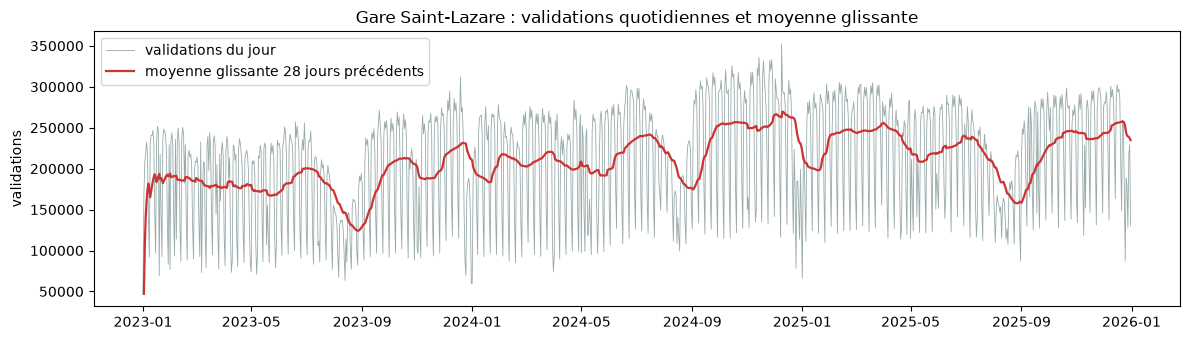

In [15]:
fig, ax = plt.subplots(figsize=(12, 3.5))
d = ds.assign(jour=pd.to_datetime(ds.jour))
ax.plot(d.jour, d.nb_vald, lw=0.6, color="#9aa", label="validations du jour")
ax.plot(d.jour, d.moy_glissante_28j, lw=1.6, color="#c33", label="moyenne glissante 28 jours précédents")
ax.set_title(f"{znom} : validations quotidiennes et moyenne glissante"); ax.legend(); ax.set_ylabel("validations")
plt.tight_layout(); plt.show()

Variable dérivée : écart relatif à la moyenne glissante 28 jours, comparé entre jours ouvrés secs et
pluvieux (RR ≥ 1 mm), sur l'ensemble des zones. Ce calcul illustre l'usage des variables ; il ne
constitue pas une estimation causale.

In [16]:
B.requete(bq, f'''
SELECT EXTRACT(YEAR FROM jour) AS annee, IF(rr_mm >= 1, 'pluvieux (RR >= 1 mm)', 'sec') AS meteo,
       COUNT(*) AS zone_jours, ROUND(AVG(nb_vald / moy_glissante_28j - 1) * 100, 2) AS ecart_moyen_pct
FROM `{G}.ds_zone_jour`
WHERE type_jour = 'Ouvré' AND jour_observe AND nb_jours_observes_28j >= 20 AND moy_glissante_28j >= 500 AND rr_mm IS NOT NULL
GROUP BY 1, 2 ORDER BY 1, 2''')

,annee,meteo,zone_jours,ecart_moyen_pct
0,2023,pluvieux (RR >= 1 mm),41083,16.73
1,2023,sec,95038,19.31
2,2024,pluvieux (RR >= 1 mm),53782,21.28
3,2024,sec,94921,16.60
4,2025,pluvieux (RR >= 1 mm),37375,19.27
5,2025,sec,115813,16.96


## 8. Exemple obligatoire — Data Analyst : indicateurs

KPI calculés par les vues `v_kpi_type_jour`, `v_kpi_mensuel_categorie` et `v_kpi_zone_annee`.

In [17]:
B.requete(bq, f"SELECT * FROM `{G}.v_kpi_type_jour` ORDER BY annee, indice_vs_ouvre DESC")

,annee,type_jour,nb_jours,validations_moyennes_par_jour,indice_vs_ouvre
0,2023,Ouvré,251,5504554.0,100.0
1,2023,Samedi,51,3681569.0,66.9
2,2023,Férié,11,2511231.0,45.6
3,2023,Dimanche,52,2490935.0,45.3
4,2024,Ouvré,252,5994436.0,100.0
5,2024,Samedi,52,4175057.0,69.6
6,2024,Dimanche,51,2899462.0,48.4
7,2024,Férié,11,2765950.0,46.1
8,2025,Ouvré,251,6710338.0,100.0
9,2025,Samedi,51,4956704.0,73.9


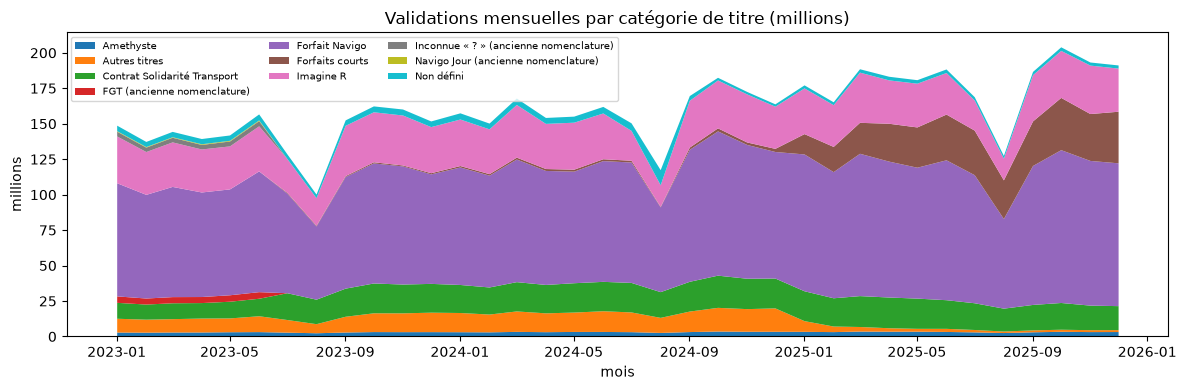

In [18]:
mensuel = B.requete(bq, f"SELECT mois, categorie_titre, nb_vald FROM `{G}.v_kpi_mensuel_categorie`")
pivot = mensuel.pivot_table(index="mois", columns="categorie_titre", values="nb_vald", aggfunc="sum").fillna(0) / 1e6
ax = pivot.plot.area(figsize=(12, 4), lw=0)
ax.set_title("Validations mensuelles par catégorie de titre (millions)"); ax.set_ylabel("millions"); ax.legend(fontsize=7, ncol=3)
plt.tight_layout(); plt.show()

In [19]:
B.requete(bq, f'''
SELECT annee, rang, nom_zone, type_zone, departement, nb_vald, jours_observes, evolution_pct
FROM `{G}.v_kpi_zone_annee` WHERE rang <= 10 AND annee = {config.annee_fin} ORDER BY rang''')

,annee,rang,nom_zone,type_zone,departement,nb_vald,jours_observes,evolution_pct
0,2025,1,Gare Saint-Lazare,railStation,75,82580548,365,1.88
1,2025,2,La Défense,railStation,92,56568160,365,32.46
2,2025,3,Châtelet,metroStation,75,52722192,365,17.11
3,2025,4,Gare de Lyon,railStation,75,48429105,365,24.04
4,2025,5,Gare Montparnasse,railStation,75,42376168,365,35.22
5,2025,6,Gare du Nord,railStation,75,35533425,365,15.43
6,2025,7,Gare de l'Est,railStation,75,30985880,365,15.10
7,2025,8,Charles de Gaulle - Étoile,railStation,75,18458340,365,58.15
8,2025,9,Les Halles,metroStation,75,17520697,365,17.96
9,2025,10,Saint-Michel Notre-Dame,railStation,75,17309222,365,18.19


In [20]:
B.requete(bq, f'''
SELECT nom_ferie, jour, nb_vald, indice_vs_ouvre_moyen FROM (
  SELECT *, ROUND(100 * nb_vald / AVG(IF(type_jour = 'Ouvré', nb_vald, NULL)) OVER (PARTITION BY annee), 1) AS indice_vs_ouvre_moyen
  FROM `{G}.v_kpi_reseau_jour`)
WHERE type_jour = 'Férié' AND annee = {config.annee_fin} ORDER BY jour''')

,nom_ferie,jour,nb_vald,indice_vs_ouvre_moyen
0,1er janvier,2025-01-01,1562324,23.3
1,Lundi de Pâques,2025-04-21,3285673,49.0
2,1er mai,2025-05-01,3547439,52.9
3,8 mai,2025-05-08,3835002,57.2
4,Ascension,2025-05-29,4330913,64.5
5,Lundi de Pentecôte,2025-06-09,4207452,62.7
6,14 juillet,2025-07-14,3645547,54.3
7,Assomption,2025-08-15,3094067,46.1
8,Toussaint,2025-11-01,4433339,66.1
9,11 novembre,2025-11-11,4004547,59.7


## 9. Exemple facultatif — Agent IA : sémantique documentée

Un agent qui interroge le Gold dispose des règles d'usage des mesures et du dictionnaire des colonnes,
lus dans BigQuery.

In [21]:
display(B.requete(bq, f"SELECT * FROM `{G}.regles_mesures` ORDER BY type_regle, objet"))
B.requete(bq, f"SELECT * FROM `{G}.v_catalogue_colonnes` WHERE table_gold = 'fait_validations_jour'")

,objet,regle,type_regle
0,nb_arrets,Non additif : ne pas sommer sur plusieurs jours ou zones.,agrégation
1,nb_vald,"Additive : se somme sur les jours, les zones et les catégories. Ne jamais faire la moyenne de moyennes.",agrégation
2,jour,"Jour d'exploitation, de 04 h 00 à 03 h 59 le lendemain : une validation à 01 h appartient à la veille.",définition
3,nb_vald,Nombre de validations d'entrée sur le réseau ferré. Une validation n'est pas un voyageur unique : une personne peut ...,définition
4,tm_c / rr_mm,Météo de la station éligible la plus proche du centre de la zone ; repli sur la moyenne IDF si la station n'a pas de...,définition
5,categorie_titre,"Harmonisée entre deux nomenclatures. Avant juillet 2023, Forfait Navigo, Contrat Solidarité Transport et Autres titr...",limite
6,categorie_titre,Rupture de classement en 2025 T1 : Forfaits courts passe d'environ 1 % à 10-19 % du volume et Autres titres de 9 % à...,limite
7,code_stif_trns / code_stif_res,Codes à lire ensemble ; ne pas en déduire une ligne commerciale ni un exploitant non confirmé.,limite
8,dim_date,Les vacances scolaires et les grèves ne sont pas renseignées : aucune source fournie.,limite
9,dim_zone,Référentiel actuel (snapshot) : une zone supprimée avant le snapshot n'y figure pas ; voir zone_referencee.,limite


,table_gold,colonne,type,description
0,fait_validations_jour,jour,DATE,Clé vers dim_date
1,fait_validations_jour,zdc_id,STRING,Clé vers dim_zone ; NULL si la source ne donne pas de zone
2,fait_validations_jour,categorie_titre,STRING,Catégorie harmonisée
3,fait_validations_jour,niveau_correspondance,STRING,Fiabilité de l'harmonisation (constante pour un jour donné)
4,fait_validations_jour,nb_vald,INT64,Somme des validations d'entrée ; additive sur toutes les dimensions ; pas un nombre de voyageurs
5,fait_validations_jour,nb_lignes_source,INT64,Lignes Silver agrégées
6,fait_validations_jour,nb_arrets,INT64,Arrêts distincts (transporteur × réseau × arrêt) ; non additif
7,fait_validations_jour,nb_vald_plancher_5,INT64,Part de nb_vald issue de valeurs « 5 ou moins »
8,fait_validations_jour,zone_referencee,BOOL,zdc_id trouvé dans le référentiel actuel des zones


## 10. Rejouabilité : exécution n° 2 avec les mêmes paramètres et le même snapshot

On calcule pour chaque table Silver et Gold le nombre de lignes et une empreinte de contenu
(XOR des `FARM_FINGERPRINT` des lignes sérialisées en JSON, indépendante de l'ordre), on relance tout
le pipeline, puis on compare.

In [22]:
empreintes_1 = empreintes(config)
execution_2 = executer(config)
empreintes_2 = empreintes(config)
print("Bronze, exécution 2 :", execution_2.bronze.statut_depot.value_counts().to_dict())
bronze_cmp = execution_1.bronze.merge(execution_2.bronze, on="chemin_gcs", suffixes=("_1", "_2"))
print("Objets Bronze :", len(bronze_cmp), "| SHA-256 identiques :", int((bronze_cmp.sha256_1 == bronze_cmp.sha256_2).sum()))
comparaison = comparer_empreintes(empreintes_1, empreintes_2)
comparaison

/home/vechoadjax/projet-python/projet TD1/.venv/lib/python3.12/site-packages/google/cloud/bigquery/_pandas_helpers.py:486: FutureWarning: Loading pandas DataFrame into BigQuery will require pandas-gbq package version 0.26.1 or greater in the future. Tried to import pandas-gbq and got: No module named 'pandas_gbq'
  warnings.warn(


Bronze, exécution 2 : {'réutilisé': 23}
Objets Bronze : 23 | SHA-256 identiques : 23


,couche,table_bq,lignes_exec1,empreinte_exec1,lignes_exec2,empreinte_exec2,lignes_identiques,contenu_identique
0,silver,validations_chargement,5635554,3430711922326421177,5635554,3430711922326421177,True,True
1,silver,validations,5635554,1785855745898038718,5635554,1785855745898038718,True,True
2,silver,validations_rejets,0,<NA>,0,<NA>,True,True
3,silver,ref_categorie_titre,16,6542262932465571457,16,6542262932465571457,True,True
4,silver,zones_correspondance,15597,7869366625966595261,15597,7869366625966595261,True,True
5,silver,jours_feries,33,-1584849903900173126,33,-1584849903900173126,True,True
6,silver,meteo_quotidienne,52180,-2294840050163065216,52180,-2294840050163065216,True,True
7,silver,stations_meteo,50,6767034389673639670,50,6767034389673639670,True,True
8,gold,dim_date,1096,1332964393494663653,1096,1332964393494663653,True,True
9,gold,dim_zone,15597,2477603209239541306,15597,2477603209239541306,True,True


In [23]:
print("Tables comparées :", len(comparaison),
      "| lignes identiques :", int(comparaison.lignes_identiques.sum()),
      "| contenu identique :", int(comparaison.contenu_identique.sum()))
assert comparaison.lignes_identiques.all() and comparaison.contenu_identique.all(), "La relance a modifié une table"

Tables comparées : 15 | lignes identiques : 15 | contenu identique : 15


## 11. Limites connues

* **Validations ≠ voyageurs** : une personne peut valider plusieurs fois ; les sorties ne sont pas comptées.
* **Référentiel des zones actuel** (snapshot 2026-10-31) : identifiants anciens remplacés seulement quand
  l'équivalence est unique ; 0,5 % du volume reste sans zone.
* **Deux nomenclatures de titres** : avant juillet 2023, trois catégories reposent sur une
  correspondance probable et trois n'ont pas d'équivalent (≈ 0,85 % du volume).
* **Censure « 5 ou moins »** en 2023 S1 (≈ 0,01 % du volume).
* **Météo** : cumul RR de 06 h UTC à 06 h UTC, décalé par rapport au jour d'exploitation (04 h–03 h 59) ;
  rattachement à la station éligible la plus proche (médiane 3,9 km).
* **Calendrier** : vacances scolaires, grèves et événements non couverts (aucune source fournie).